# Fry-ndship

Flag: **`SIGMOID_PREDICTION`**

Edge length = 0.41 × perimeter + ditch + hedge. What is left over spells PREDICTION. Two more words sit one layer up (REGRESSION in the ditch, SUPERVISION in the hedge).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid')
d = pd.read_csv('../task_belgium/potato_fields.csv')
print(d.shape, '| missing:', d.isna().sum().sum())
d.head()

(3869, 12) | missing: 0


,field_id,crop_code,crop,farm_type,lat,lon,area_ha,long_side_m,ditch_m,hedge_m,edge_m,fence_quote_eur
0,VLA24-0001,901,Aardappelen (geplande oogst vanaf 1/9),Mixed,51.20,3.78,1.0225,177.5,237.7,18.3,448.79,4404
1,VLA24-0002,901,Aardappelen (geplande oogst vanaf 1/9),Arable,50.95,4.22,0.9423,156.8,225.7,18.8,422.31,4155
2,VLA24-0003,901,Aardappelen (geplande oogst vanaf 1/9),Livestock,51.00,3.60,1.0263,241.0,294.0,24.2,550.74,5362
3,VLA24-0004,901,Aardappelen (geplande oogst vanaf 1/9),Arable,50.84,4.57,4.5395,376.3,501.2,39.2,947.94,9096
4,VLA24-0005,901,Aardappelen (geplande oogst vanaf 1/9),Arable,50.77,3.43,0.5617,110.7,175.8,12.6,320.79,3200


In [2]:
d.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crop_code,3869.0,901.48,1.30,901.00,901.00,901.00,901.00,908.00
lat,3869.0,50.99,0.17,50.69,50.86,50.97,51.12,51.48
lon,3869.0,3.70,0.80,2.57,3.07,3.50,4.20,5.83
area_ha,3869.0,2.70,1.81,0.21,1.15,2.34,3.95,8.06
long_side_m,3869.0,260.23,103.67,68.80,176.40,257.30,337.30,550.10
ditch_m,3869.0,357.35,127.48,117.70,252.30,356.90,463.90,599.40
hedge_m,3869.0,28.59,10.21,9.30,20.30,28.90,36.80,48.10
edge_m,3869.0,678.97,241.71,239.29,479.27,682.52,884.78,1123.55
fence_quote_eur,3869.0,6567.30,2272.06,2434.00,4690.00,6601.00,8502.00,10746.00


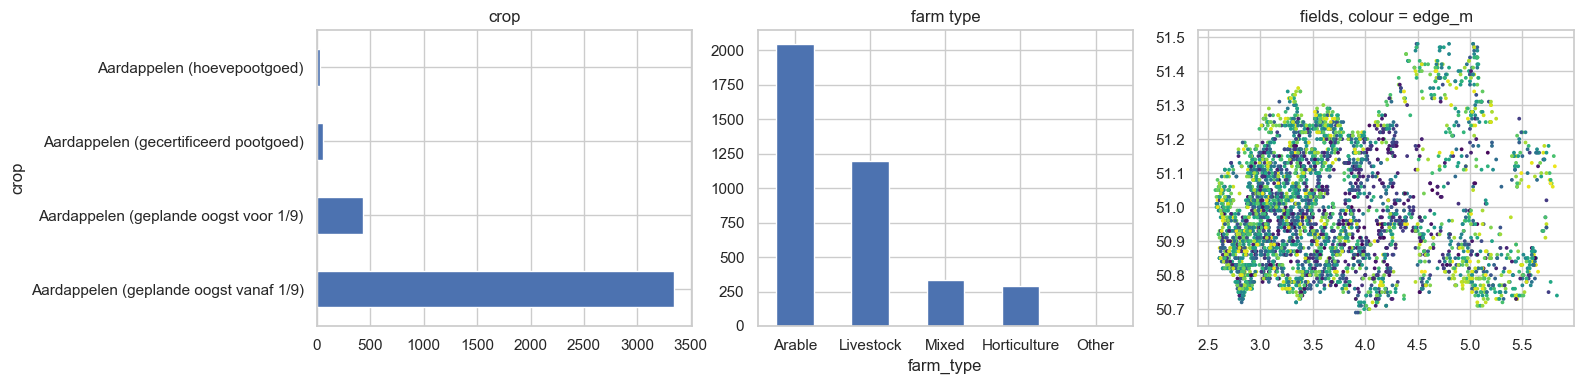

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
d.crop.value_counts().plot.barh(ax=ax[0], title='crop')
d.farm_type.value_counts().plot.bar(ax=ax[1], title='farm type', rot=0)
ax[2].scatter(d.lon, d.lat, s=3, c=d.edge_m, cmap='viridis'); ax[2].set_title('fields, colour = edge_m')
plt.tight_layout(); plt.show()

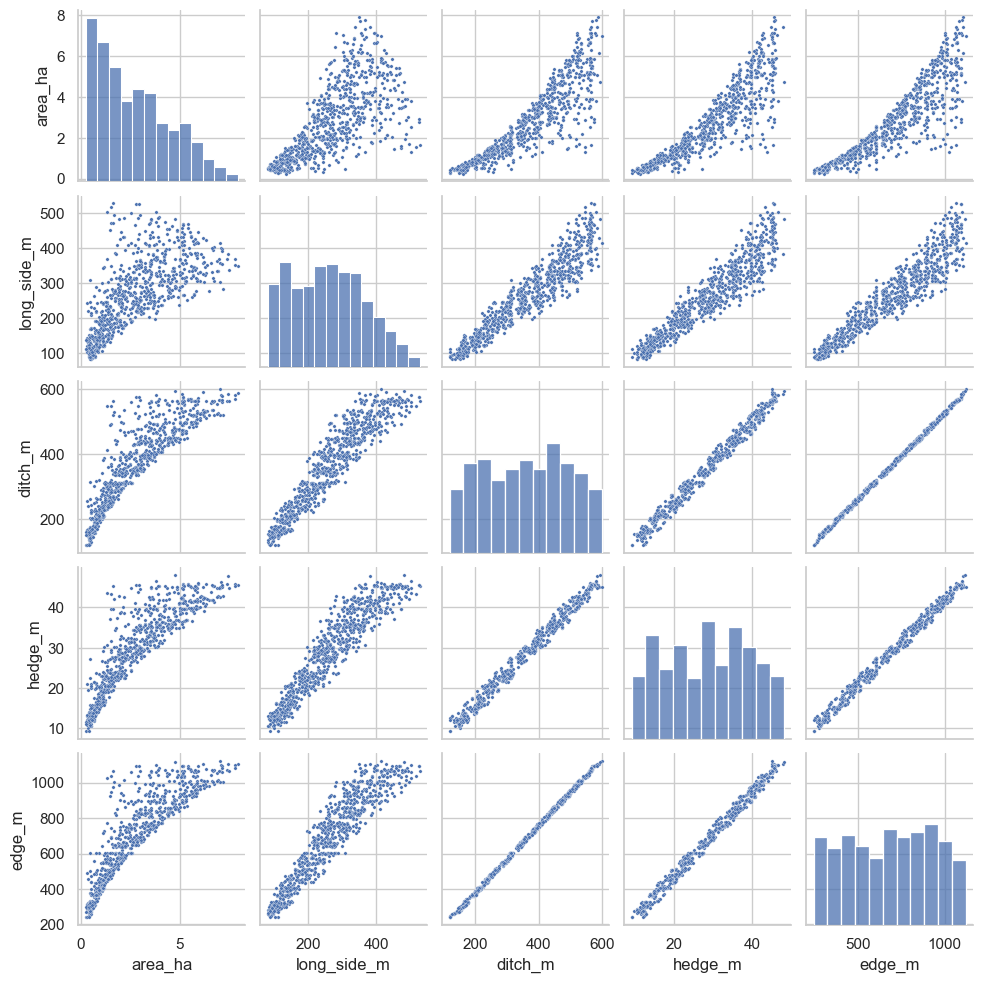

In [4]:
sns.pairplot(d[['area_ha', 'long_side_m', 'ditch_m', 'hedge_m', 'edge_m']].sample(800, random_state=0),
             plot_kws={'s': 6}, height=2)
plt.show()

## The co-op's model

Linear model on what the farmers declare. 99.9% R², but the residuals are curved: area and long side are not lengths.

R2 0.9991


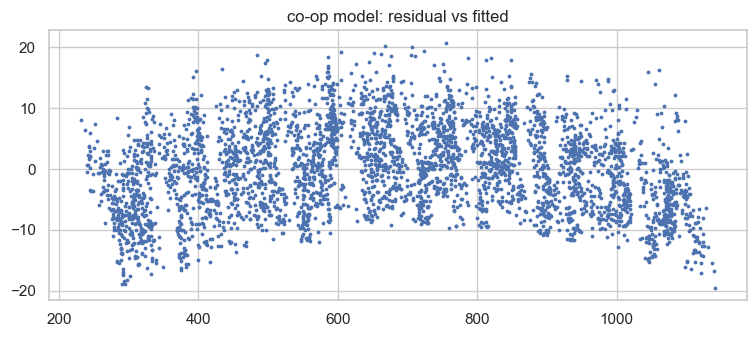

In [5]:
coop = smf.ols('edge_m ~ area_ha + long_side_m + ditch_m', d).fit()
print('R2', round(coop.rsquared, 4))
plt.figure(figsize=(9, 3.5)); plt.scatter(coop.fittedvalues, coop.resid, s=3)
plt.title('co-op model: residual vs fitted'); plt.show()

## Geometry

Short side = area / long side, perimeter of the rectangle = 2·(long + short).

In [6]:
d['short_side_m'] = d.area_ha * 1e4 / d.long_side_m
d['perimeter_m'] = 2 * (d.long_side_m + d.short_side_m)
d['quote_per_m'] = d.fence_quote_eur / d.edge_m
d[['short_side_m', 'perimeter_m', 'quote_per_m']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
short_side_m,3869.0,97.12,45.29,7.92,61.65,91.22,126.51,252.63
perimeter_m,3869.0,714.70,254.22,266.19,504.78,719.00,924.26,1168.14
quote_per_m,3869.0,9.72,0.14,9.56,9.61,9.67,9.79,10.17


In [7]:
rows = []
for f in ['edge_m ~ perimeter_m', 'edge_m ~ perimeter_m + ditch_m', 'edge_m ~ perimeter_m + ditch_m + hedge_m']:
    m = smf.ols(f, d).fit()
    rows.append({'model': f, 'R2': round(m.rsquared, 7), 'resid_sd': round(m.resid.std(), 3),
                 **m.params.round(3).to_dict()})
pd.DataFrame(rows)

,model,R2,resid_sd,Intercept,perimeter_m,ditch_m,hedge_m
0,edge_m ~ perimeter_m,0.998367,9.767,-0.000,0.95,NaN,NaN
1,edge_m ~ perimeter_m + ditch_m,0.999984,0.957,-0.001,0.45,1.0,NaN
2,edge_m ~ perimeter_m + ditch_m + hedge_m,1.000000,0.057,0.000,0.41,1.0,1.0


With ditch and hedge the fit is exact up to ±0.1 m: edge = 0.41·perimeter + ditch + hedge.

## Residuals

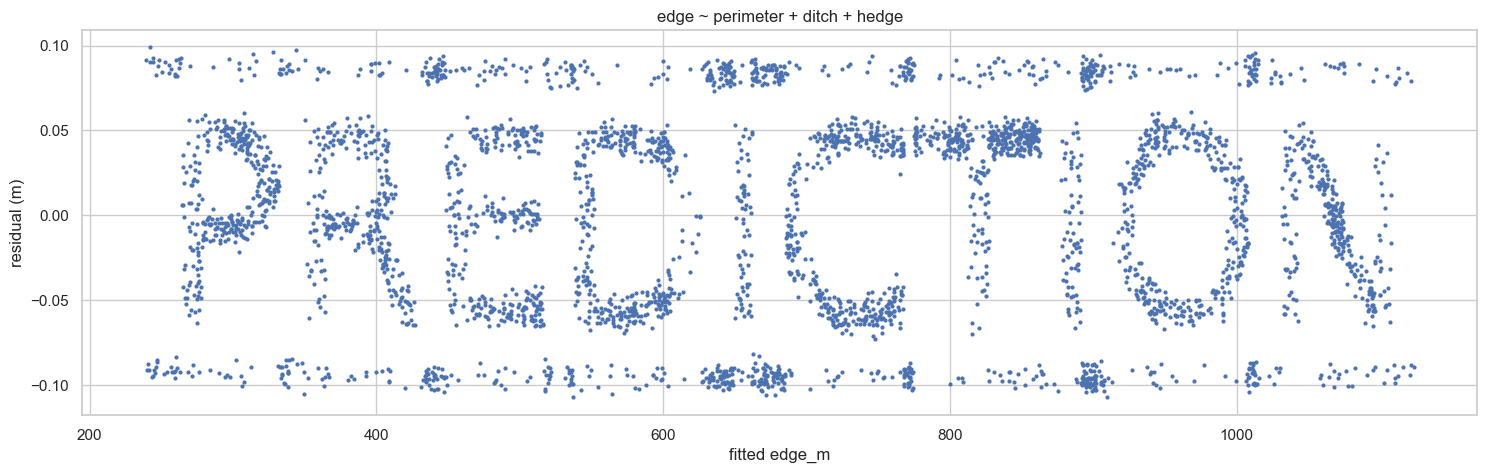

In [8]:
full = smf.ols('edge_m ~ perimeter_m + ditch_m + hedge_m', d).fit()
plt.figure(figsize=(18, 5))
plt.scatter(full.fittedvalues, full.resid, s=4)
plt.xlabel('fitted edge_m'); plt.ylabel('residual (m)')
plt.title('edge ~ perimeter + ditch + hedge')
plt.savefig('edge_residuals.png', dpi=120, bbox_inches='tight'); plt.show()

**PREDICTION** — in Mariette's edge measurements, once every dimension is in the model.

The other columns carry words too:

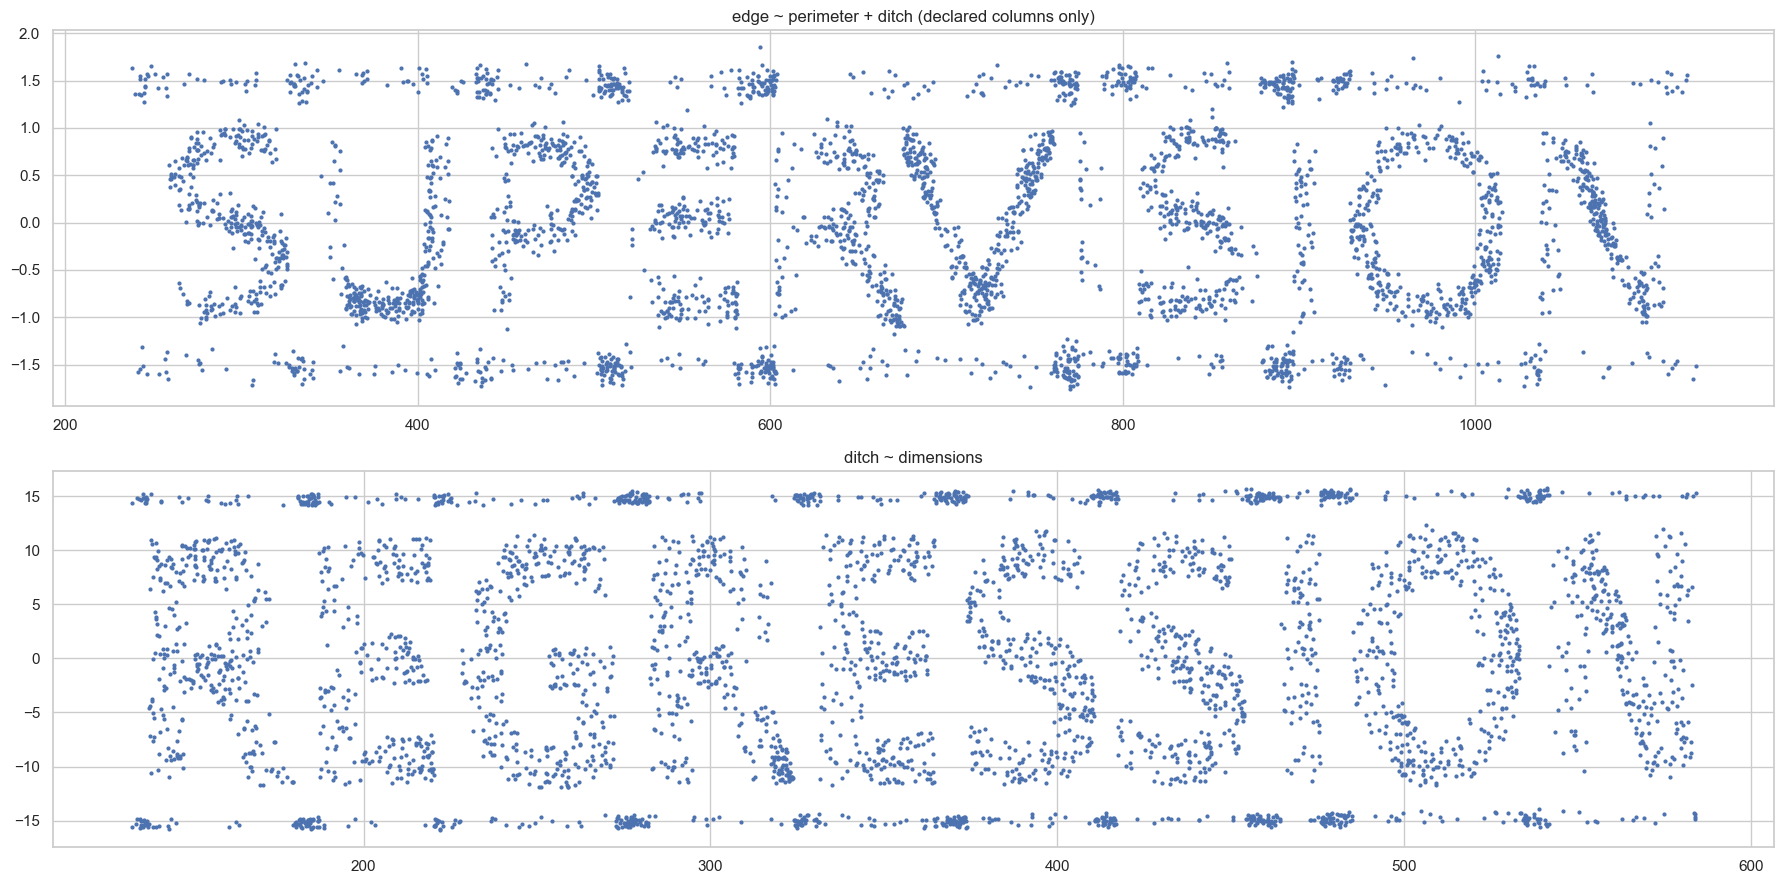

In [9]:
decl = smf.ols('edge_m ~ perimeter_m + ditch_m', d).fit()
ditch = smf.ols('ditch_m ~ perimeter_m + long_side_m + short_side_m', d).fit()
fig, ax = plt.subplots(2, 1, figsize=(18, 9))
ax[0].scatter(decl.fittedvalues, decl.resid, s=4); ax[0].set_title('edge ~ perimeter + ditch (declared columns only)')
ax[1].scatter(ditch.fittedvalues, ditch.resid, s=4); ax[1].set_title('ditch ~ dimensions')
plt.tight_layout(); plt.savefig('other_layers.png', dpi=100); plt.show()

- leaving the hedge out, the edge residual is the hedge's own pattern: **SUPERVISION**
- the farmers' ditch lengths: **REGRESSION**

Both come from columns that are not the edge measurement. The task asks for the word in Mariette's measurements after modelling edge length, so the answer is PREDICTION.

The contractor's quote is just 185 € + 9.40 €/m of edge, nothing hidden there:

In [10]:
q = smf.ols('fence_quote_eur ~ edge_m', d).fit()
print(q.params.round(3).to_dict(), 'R2', round(q.rsquared, 8))

{'Intercept': 185.007, 'edge_m': 9.4} R2 0.99999998
